In [23]:
import ast
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from huggingface_hub import hf_hub_download

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")

In [4]:
mams = load_dataset("NEUDM/mams")

mams

DatasetDict({
    train: Dataset({
        features: ['task_type', 'dataset', 'input', 'output', 'situation', 'label', 'extra', 'instruction'],
        num_rows: 7446
    })
    validation: Dataset({
        features: ['task_type', 'dataset', 'input', 'output', 'situation', 'label', 'extra', 'instruction'],
        num_rows: 900
    })
    test: Dataset({
        features: ['task_type', 'dataset', 'input', 'output', 'situation', 'label', 'extra', 'instruction'],
        num_rows: 900
    })
})

In [5]:
for split in mams:
    print(f"{split}: {len(mams[split])} samples")
    print(mams[split].column_names)
    print()

train: 7446 samples
['task_type', 'dataset', 'input', 'output', 'situation', 'label', 'extra', 'instruction']

validation: 900 samples
['task_type', 'dataset', 'input', 'output', 'situation', 'label', 'extra', 'instruction']

test: 900 samples
['task_type', 'dataset', 'input', 'output', 'situation', 'label', 'extra', 'instruction']



In [6]:
for i in range(3):
    print(f"Example {i + 1}")
    print(mams["train"][i])
    print("-" * 100)

Example 1
{'task_type': 'generation', 'dataset': 'mams', 'input': ["It might be the best sit down food I've had in the area, so if you are going to the upright citizen brigade, or the garden, it could be just the place for you."], 'output': "[['food', 'positive'], ['place', 'neutral']]", 'situation': 'none', 'label': '', 'extra': '', 'instruction': ' Task: Extracting aspect terms\' aspect categories and their corresponding sentiment polarities. Input: A sentence. Output: A list of 2-tuples, where each tuple contains the extracted aspect category and their corresponding sentiment polarity. Supplement: "Null" means that there is no occurrence in the sentence. Example:  Input: "Hostess was extremely accommodating when we arrived an hour early for our reservation."  Output: [[\'staff\', \'positive\'], [\'miscellaneous\', \'neutral\']] '}
----------------------------------------------------------------------------------------------------
Example 2
{'task_type': 'generation', 'dataset': 'mam

In [24]:
DOMAINS = [
    "restaurant",
    "hotel",
    "laptop"
]

LANGUAGES = [
    "en",
    "ru",
    "de"
]

SPLITS = {
    "train": "train",
    "validation": "dev",
    "test": "test"
}

In [25]:
def parse_m_absa_record(record):
    if "####" not in record:
        return record.strip(), []

    sentence, annotations = record.split("####", maxsplit=1)

    try:
        annotations = ast.literal_eval(annotations)
    except (ValueError, SyntaxError):
        annotations = []

    return sentence.strip(), annotations

In [26]:
def load_m_absa_file(domain, language, split):
    filename = f"{domain}/{language}/{split}.txt"

    path = hf_hub_download(
        repo_id="Multilingual-NLP/M-ABSA",
        filename=filename,
        repo_type="dataset"
    )

    with open(path, "r", encoding="utf-8") as f:
        records = [line.rstrip("\n") for line in f]

    return records

In [27]:
restaurant_en_train = load_m_absa_file(
    domain="restaurant",
    language="en",
    split="train"
)

print("Number of records:", len(restaurant_en_train))

for record in restaurant_en_train[:5]:
    print(record)
    print("-" * 100)

Number of records: 1264
We have gone for dinner only a few times but the same great quality and service is given .####[['service', 'service general', 'positive'], ['dinner', 'food quality', 'positive']]
----------------------------------------------------------------------------------------------------
Its dark , and cozy . . there is always jazz music playing when we go .####[['NULL', 'ambience general', 'positive']]
----------------------------------------------------------------------------------------------------
This place has great indian chinese food .####[['indian chinese food', 'food quality', 'positive']]
----------------------------------------------------------------------------------------------------
Not what I would expect for the price and prestige of this location .####[['location', 'restaurant prices', 'neutral'], ['location', 'restaurant miscellaneous', 'neutral']]
----------------------------------------------------------------------------------------------------
Fi

In [29]:
def parse_m_absa_records(records, domain, language, split):
    """
    Convert raw M-ABSA records into a flat DataFrame.

    One row = one annotated aspect.
    """

    rows = []

    for record in records:
        sentence, annotations = parse_m_absa_record(record)

        for annotation in annotations:

            if len(annotation) != 3:
                continue

            aspect, category, sentiment = annotation

            rows.append({
                "text": sentence,
                "aspect": aspect,
                "category": category,
                "sentiment": sentiment,
                "domain": domain,
                "language": language,
                "split": split
            })

    return pd.DataFrame(rows)

In [30]:
restaurant_en_train_df = parse_m_absa_records(
    records=restaurant_en_train,
    domain="restaurant",
    language="en",
    split="train"
)

print("Shape:", restaurant_en_train_df.shape)

restaurant_en_train_df.head(10)

,text,aspect,category,sentiment,domain,language,split
0,We have gone for dinner only a few times but the same great quality and service is given .,service,service general,positive,restaurant,en,train
1,We have gone for dinner only a few times but the same great quality and service is given .,dinner,food quality,positive,restaurant,en,train
2,"Its dark , and cozy . . there is always jazz music playing when we go .",NULL,ambience general,positive,restaurant,en,train
3,This place has great indian chinese food .,indian chinese food,food quality,positive,restaurant,en,train
4,Not what I would expect for the price and prestige of this location .,location,restaurant prices,neutral,restaurant,en,train
5,Not what I would expect for the price and prestige of this location .,location,restaurant miscellaneous,neutral,restaurant,en,train
6,Finally a reliable Chinese restaurant !,Chinese restaurant,restaurant general,positive,restaurant,en,train
7,"The lobster knuckles ( special of the day ) were ok , but pretty tasteless .",lobster knuckles,food style_options,neutral,restaurant,en,train
8,"The lobster knuckles ( special of the day ) were ok , but pretty tasteless .",lobster knuckles,food quality,negative,restaurant,en,train
9,The menu is fairly simple without much descriptions .,menu,food style_options,neutral,restaurant,en,train


In [31]:
print("Columns:")
print(restaurant_en_train_df.columns.tolist())

print("\nSentiments:")
print(restaurant_en_train_df["sentiment"].value_counts())

print("\nCategories:")
print(restaurant_en_train_df["category"].value_counts().head(10))

Columns:
['text', 'aspect', 'category', 'sentiment', 'domain', 'language', 'split']

Sentiments:
sentiment
positive    1369
negative     558
neutral       62
Name: count, dtype: int64

Categories:
category
food quality                693
service general             356
restaurant general          308
ambience general            222
food style_options           97
restaurant miscellaneous     81
food prices                  62
restaurant prices            61
drinks quality               40
drinks style_options         30
Name: count, dtype: int64


In [32]:
restaurant_en_train_df[
    restaurant_en_train_df["text"].str.contains(
        "dinner",
        case=False,
        na=False
    )
].head()

,text,aspect,category,sentiment,domain,language,split
0,We have gone for dinner only a few times but the same great quality and service is given .,service,service general,positive,restaurant,en,train
1,We have gone for dinner only a few times but the same great quality and service is given .,dinner,food quality,positive,restaurant,en,train
39,"Sometimes tables do n't understand his sense of humor but it 's refreshing to have a server who has personality , professionalism , and respects the privacy of your dinner .",server,service general,positive,restaurant,en,train
40,"Sometimes tables do n't understand his sense of humor but it 's refreshing to have a server who has personality , professionalism , and respects the privacy of your dinner .",server,service general,positive,restaurant,en,train
41,"Sometimes tables do n't understand his sense of humor but it 's refreshing to have a server who has personality , professionalism , and respects the privacy of your dinner .",server,service general,positive,restaurant,en,train


In [33]:
all_data = []

for domain in DOMAINS:
    for language in LANGUAGES:
        for split_name, file_split in SPLITS.items():

            print(f"Loading: {domain}/{language}/{file_split}")

            records = load_m_absa_file(
                domain=domain,
                language=language,
                split=file_split
            )

            df = parse_m_absa_records(
                records=records,
                domain=domain,
                language=language,
                split=split_name
            )

            all_data.append(df)

m_absa_selected = pd.concat(
    all_data,
    ignore_index=True
)

print("\nFinal shape:", m_absa_selected.shape)


Final shape: (27587, 7)


In [34]:
print("Total samples:", len(m_absa_selected))

print("\nBy split:")
print(m_absa_selected["split"].value_counts())

print("\nBy language:")
print(m_absa_selected["language"].value_counts())

print("\nBy domain:")
print(m_absa_selected["domain"].value_counts())

Total samples: 27587

By split:
split
train         16115
test           7577
validation     3895
Name: count, dtype: int64

By language:
language
en    9210
ru    9193
de    9184
Name: count, dtype: int64

By domain:
domain
restaurant    9843
hotel         8880
laptop        8864
Name: count, dtype: int64


In [35]:
pd.crosstab(
    m_absa_selected["domain"],
    m_absa_selected["language"]
)

language,de,en,ru
domain,,,
hotel,2960,2960,2960
laptop,2954,2955,2955
restaurant,3270,3295,3278


In [36]:
print(
    m_absa_selected["sentiment"].value_counts()
)

sentiment
positive    19702
negative     6747
neutral      1135
conflict        3
Name: count, dtype: int64


In [37]:
print(
    m_absa_selected["sentiment"].unique()
)

<ArrowStringArray>
['positive', 'neutral', 'negative', 'conflict']
Length: 4, dtype: str


In [38]:
m_absa_selected.head(10)

,text,aspect,category,sentiment,domain,language,split
0,We have gone for dinner only a few times but the same great quality and service is given .,service,service general,positive,restaurant,en,train
1,We have gone for dinner only a few times but the same great quality and service is given .,dinner,food quality,positive,restaurant,en,train
2,"Its dark , and cozy . . there is always jazz music playing when we go .",NULL,ambience general,positive,restaurant,en,train
3,This place has great indian chinese food .,indian chinese food,food quality,positive,restaurant,en,train
4,Not what I would expect for the price and prestige of this location .,location,restaurant prices,neutral,restaurant,en,train
5,Not what I would expect for the price and prestige of this location .,location,restaurant miscellaneous,neutral,restaurant,en,train
6,Finally a reliable Chinese restaurant !,Chinese restaurant,restaurant general,positive,restaurant,en,train
7,"The lobster knuckles ( special of the day ) were ok , but pretty tasteless .",lobster knuckles,food style_options,neutral,restaurant,en,train
8,"The lobster knuckles ( special of the day ) were ok , but pretty tasteless .",lobster knuckles,food quality,negative,restaurant,en,train
9,The menu is fairly simple without much descriptions .,menu,food style_options,neutral,restaurant,en,train


In [39]:
m_absa_selected.sample(
    10,
    random_state=SEED
)

,text,aspect,category,sentiment,domain,language,split
11402,"We had just come from hot and somewhat cramped stays in London and Paris , so we found the air conditioning and spacious room a much needed luxury .",room,rooms design_features,positive,hotel,en,train
14316,"В 50 метрах от Кафедрального собора, в 200 метрах от бульвара Лас-Рамблас и в 400 метрах от площади Каталонии, которая является центральным пунктом прибытия поездов и автобусов из аэропорта.",NULL,location general,positive,hotel,ru,train
20636,which is really sad because in the time i could actually use the chromebook i absolutely loved it .,chromebook,LAPTOP#GENERAL,negative,laptop,en,validation
11373,Great Hotel,Hotel,hotel general,positive,hotel,en,train
6593,"Ausgezeichnet Atmosphäre, lecker Gerichte, gut und freundlich Service.",Gerichte,food quality,positive,restaurant,de,train
428,"However , I think Jeckll and Hydes t is one of those places that is fun to do once .",Jeckll and Hydes,restaurant general,positive,restaurant,en,train
16518,"toll Lage Dieses Hotel hat eine fantastische Lage, in der Nähe der Geschäfte, des Busbahnhofs und des Doms.",Lage,location general,positive,hotel,de,train
17531,Essen und der Rest des Resorts sind nichts Besonderes.,Essen,food_drinks quality,neutral,hotel,de,validation
5503,"Самая свежая, лучший ассортимент и самая быстрая доставка.",NULL,food style_options,positive,restaurant,ru,validation
5345,"Соус был водянистым, а еда не имела особого вкуса.",Соус,food quality,negative,restaurant,ru,validation


In [40]:
print("Before filtering:")
print(m_absa_selected["sentiment"].value_counts())

m_absa_selected = m_absa_selected[
    m_absa_selected["sentiment"].isin(
        ["positive", "neutral", "negative"]
    )
].reset_index(drop=True)

print("\nAfter filtering:")
print(m_absa_selected["sentiment"].value_counts())

print("\nFinal shape:", m_absa_selected.shape)

Before filtering:
sentiment
positive    19702
negative     6747
neutral      1135
conflict        3
Name: count, dtype: int64

After filtering:
sentiment
positive    19702
negative     6747
neutral      1135
Name: count, dtype: int64

Final shape: (27584, 7)


In [41]:
sentiment_language = pd.crosstab(
    m_absa_selected["language"],
    m_absa_selected["sentiment"]
)

sentiment_language

sentiment,negative,neutral,positive
language,,,
de,2248,378,6557
en,2250,379,6580
ru,2249,378,6565


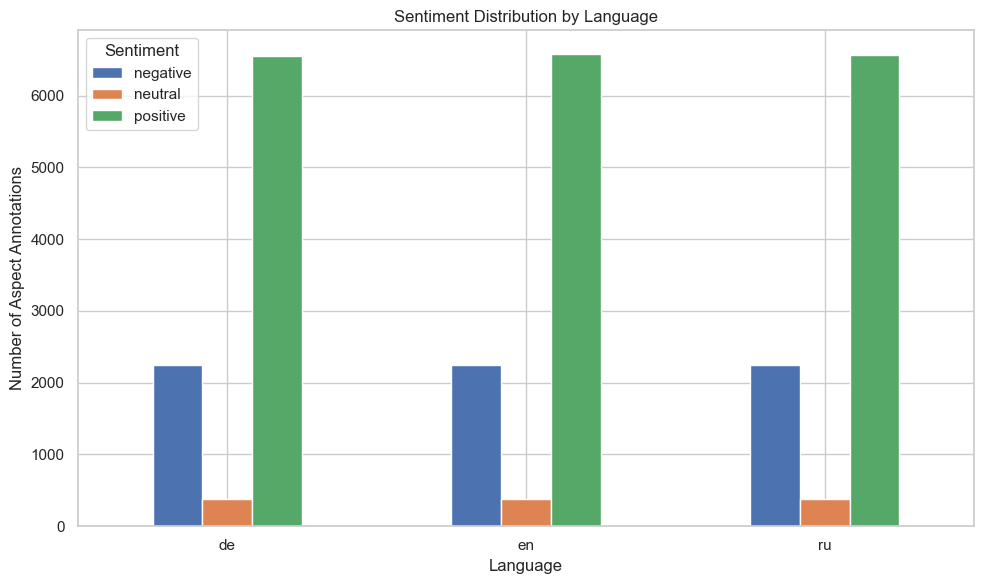

In [42]:
sentiment_language.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sentiment Distribution by Language")
plt.xlabel("Language")
plt.ylabel("Number of Aspect Annotations")
plt.xticks(rotation=0)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

In [43]:
sentiment_domain = pd.crosstab(
    m_absa_selected["domain"],
    m_absa_selected["sentiment"]
)

sentiment_domain

sentiment,negative,neutral,positive
domain,,,
hotel,1356,231,7290
laptop,2762,531,5571
restaurant,2629,373,6841


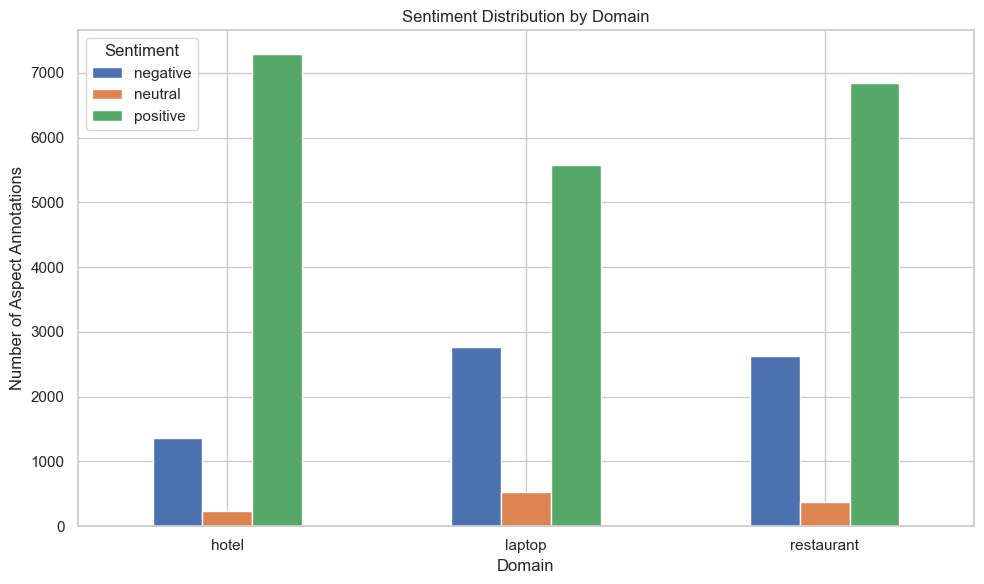

In [44]:
sentiment_domain.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sentiment Distribution by Domain")
plt.xlabel("Domain")
plt.ylabel("Number of Aspect Annotations")
plt.xticks(rotation=0)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

In [45]:
for domain in DOMAINS:
    print(f"\n{'=' * 60}")
    print(f"{domain.upper()}")
    print(f"{'=' * 60}")

    print(
        m_absa_selected[
            m_absa_selected["domain"] == domain
        ]["category"]
        .value_counts()
        .head(15)
    )


RESTAURANT
category
food quality                3535
service general             1742
restaurant general          1494
ambience general            1059
food style_options           543
restaurant miscellaneous     348
food prices                  306
restaurant prices            286
drinks quality               204
drinks style_options         138
location general             116
drinks prices                 69
food general                   3
Name: count, dtype: int64

HOTEL
category
hotel general             2088
service general           1554
location general          1236
rooms design_features      540
rooms general              453
food_drinks quality        348
hotel prices               330
rooms cleanliness          297
facilities general         240
rooms comfort              216
hotel design_features      195
hotel comfort              174
room_amenities general     138
hotel cleanliness          135
rooms quality              117
Name: count, dtype: int64

LAPTOP
category


In [46]:
m_absa_selected["text_length"] = (
    m_absa_selected["text"]
    .str.len()
)

In [47]:
m_absa_selected["word_count"] = (
    m_absa_selected["text"]
    .str.split()
    .str.len()
)

In [49]:
m_absa_selected[
    ["text", "text_length", "word_count"]
].head(10)

,text,text_length,word_count
0,We have gone for dinner only a few times but the same great quality and service is given .,90,19
1,We have gone for dinner only a few times but the same great quality and service is given .,90,19
2,"Its dark , and cozy . . there is always jazz music playing when we go .",71,17
3,This place has great indian chinese food .,42,8
4,Not what I would expect for the price and prestige of this location .,69,14
5,Not what I would expect for the price and prestige of this location .,69,14
6,Finally a reliable Chinese restaurant !,39,6
7,"The lobster knuckles ( special of the day ) were ok , but pretty tasteless .",76,16
8,"The lobster knuckles ( special of the day ) were ok , but pretty tasteless .",76,16
9,The menu is fairly simple without much descriptions .,53,9


In [50]:
m_absa_selected[
    ["text_length", "word_count"]
].describe()

,text_length,word_count
count,27584.000000,27584.000000
mean,91.203741,15.278386
std,61.871496,10.450643
min,3.000000,1.000000
25%,50.000000,8.000000
50%,77.000000,13.000000
75%,117.000000,20.000000
max,639.000000,123.000000


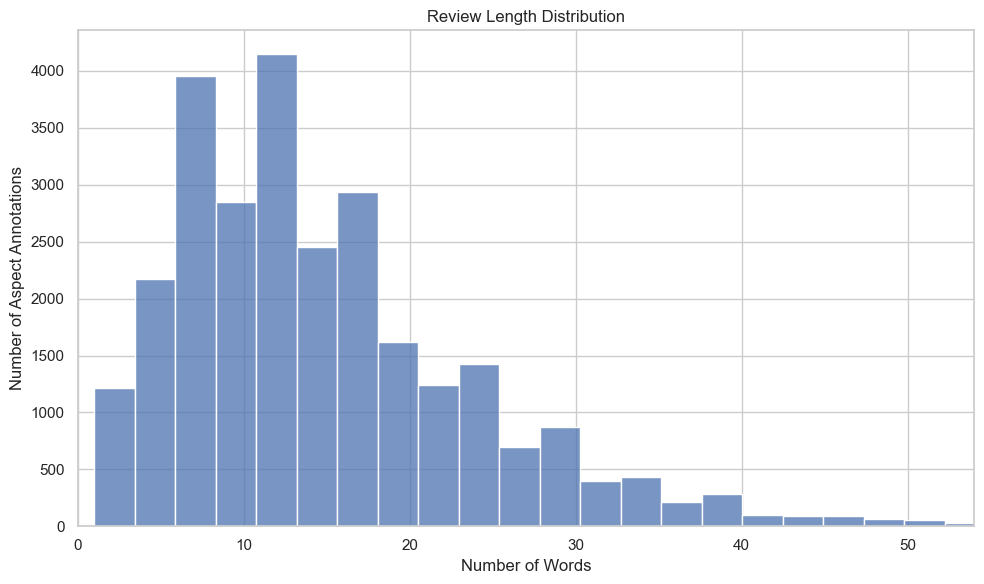

In [51]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=m_absa_selected,
    x="word_count",
    bins=50
)

plt.title("Review Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Aspect Annotations")
plt.xlim(0, m_absa_selected["word_count"].quantile(0.99))

plt.tight_layout()
plt.show()

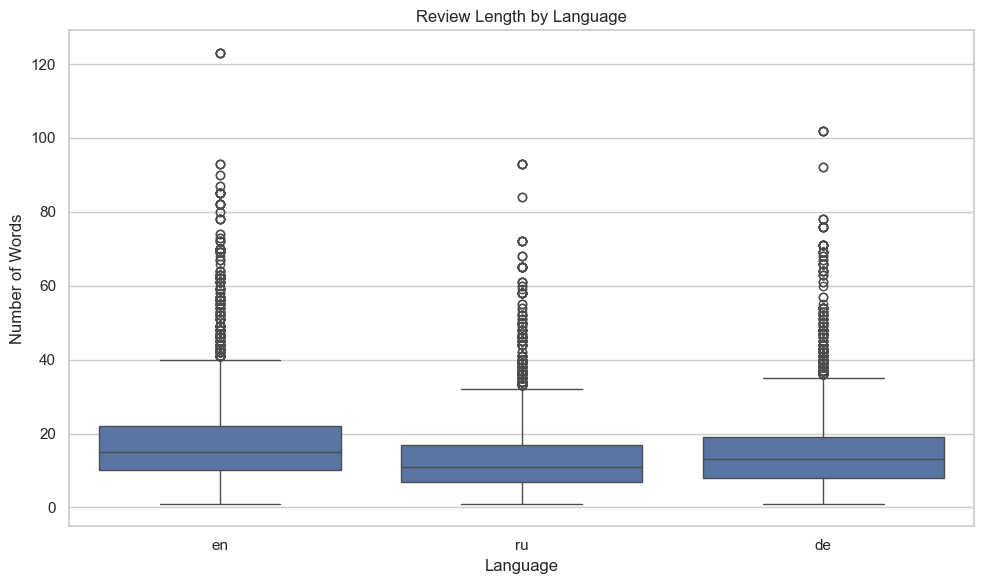

In [52]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=m_absa_selected,
    x="language",
    y="word_count"
)

plt.title("Review Length by Language")
plt.xlabel("Language")
plt.ylabel("Number of Words")

plt.tight_layout()
plt.show()

In [53]:
m_absa_selected.groupby("language")[
    ["text_length", "word_count"]
].agg(["mean", "median", "std"])

text_length                   word_count                  
                mean median        std       mean median        std
language                                                           
de         97.788522   84.0  65.856472  14.987259   13.0  10.071437
en         85.166902   73.0  56.742964  17.415463   15.0  11.551026
ru         90.673412   76.0  62.046321  13.428198   11.0   9.201894

In [54]:
m_absa_selected.groupby("domain")[
    ["text_length", "word_count"]
].agg(["mean", "median", "std"])

text_length                   word_count                  
                  mean median        std       mean median        std
domain                                                               
hotel       102.907964   87.0  72.643710  16.881942   14.0  12.190579
laptop       86.435244   74.0  56.111152  14.626579   13.0   9.568237
restaurant   84.942396   74.0  54.321537  14.419181   12.0   9.283203

In [55]:
reviews = (
    m_absa_selected[
        ["text", "domain", "language", "split"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Unique reviews:", len(reviews))

Unique reviews: 17853


In [56]:
aspects_per_review = (
    m_absa_selected
    .groupby(
        ["text", "domain", "language", "split"]
    )
    .size()
    .reset_index(name="aspect_count")
)

aspects_per_review.head(10)

,text,domain,language,split,aspect_count
0,$ 170 down the toilet ...,restaurant,en,train,1
1,$ 20 for all you can eat sushi can not be beaten .,restaurant,en,validation,1
2,"$ 6 and there is much tasty food , all of it fresh and continually refilled .",restaurant,en,validation,3
3,$ 6 with tip .,restaurant,en,test,1
4,"$31 / day . - The restaurant ( Cafe 15 ) had very slow service when I eat there , even though they weren ' t doing much business .",hotel,en,validation,1
5,"' what a bunch of whiners , ' i concluded about all the people who slammed the keyboard .",laptop,en,train,1
6,"( * cough ' quizlet ' cough * ) i use this hooked up to my mobile hotspot from my cell phone mainly , and it allows me access anywhere i have cell service .",laptop,en,train,1
7,"( * hust ' Quizlet ' hust * ) ich verwende dies hauptsächlich verbunden mit dem mobilen Hotspot meines Handys und es ermöglicht mir überall Zugriff, wo ich Mobilfunkempfang habe.",laptop,de,train,1
8,"( *кашляет 'quizlet' кашляет *) Я использую это, в основном, подключенным к моей мобильной точке доступа с моего сотового телефона, и это позволяет мне получать доступ отовсюду, где есть сотовая с...",laptop,ru,train,1
9,( Always ask the bartender for the SEASONAL beer ! ! !,restaurant,en,train,1


In [57]:
aspects_per_review["aspect_count"].describe()

count    17853.000000
mean         1.545062
std          0.922282
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         12.000000
Name: aspect_count, dtype: float64

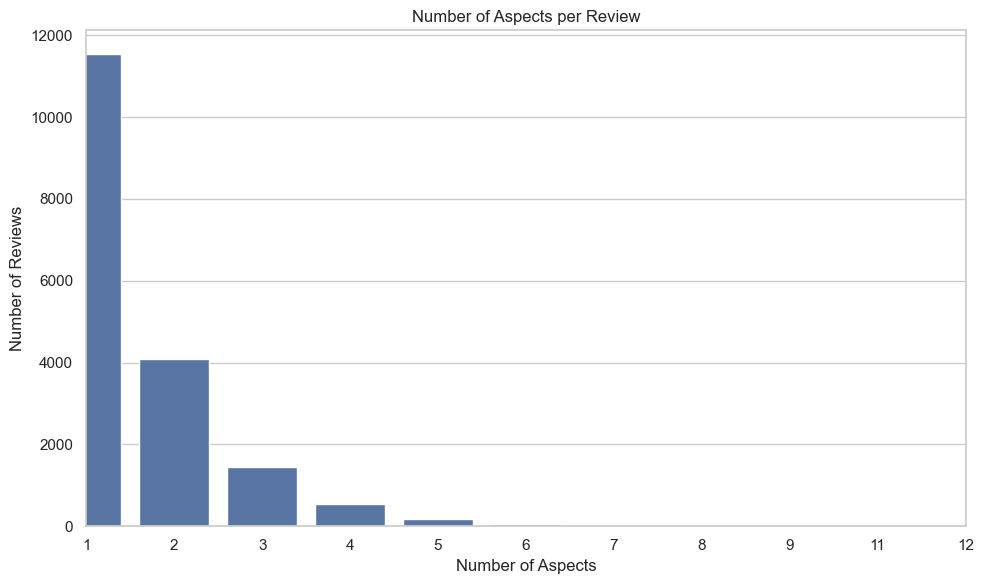

In [58]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=aspects_per_review,
    x="aspect_count"
)

plt.title("Number of Aspects per Review")
plt.xlabel("Number of Aspects")
plt.ylabel("Number of Reviews")

plt.xlim(
    0,
    min(
        10,
        aspects_per_review["aspect_count"].max()
    )
)

plt.tight_layout()
plt.show()

In [59]:
multi_aspect_reviews = (
    aspects_per_review[
        aspects_per_review["aspect_count"] >= 3
    ]
    .sort_values(
        "aspect_count",
        ascending=False
    )
)

multi_aspect_reviews.head(10)

,text,domain,language,split,aspect_count
6826,"Tolle Aussicht auf den Hafen/die Stadt, toll Service, toll Hotel, toll Zimmer, toll Essen, toll Bar, toll Einrichtungen, toll Lage, sauber, komfortabel, modern und das Personal war immer so hilfsb...",hotel,de,train,12
3194,"Great views of the harbour / city , great service , great hotel , great room , great food , great bar , great facilities , great location , clean , comfortable , modern and the staff were always a...",hotel,en,train,12
12294,"Великолепный вид на гавань/город, великолепно обслуживание, великолепно отель, великолепно номер, великолепно еда, великолепно бар, великолепно удобства, великолепно расположение, чисто, комфортно...",hotel,ru,train,12
4394,"It is a fairly new tall and narrow building squeezed between two larger ones so there ' s little natural light , but the rooms are what you ' d typically expect from a Marriott Courtyard , and sur...",hotel,en,validation,11
15003,"Это довольно новое высокое и узкое здание, зажатое между двумя большими зданиями, так что естественного света в нем мало, но номера соответствуют тому, что обычно ожидаешь от Marriott Courtyard, и...",hotel,ru,validation,11
2591,"Es ist ein recht neues, hohes und schmales Gebäude, das zwischen zwei größeren Gebäuden eingezwängt ist, sodass es wenig natürliches Licht gibt, aber die Zimmer sind so, wie man es normalerweise v...",hotel,de,validation,11
13033,"Лучший отель, в котором мы когда-либо останавливались. Этот отель просто великолепен - идеальное расположение (10 минут ходьбы до главной торговой улицы и 15-20 минут ходьбы до Запретного города/п...",hotel,ru,train,9
1623,"Das beste Hotel, in dem wir je übernachtet haben. Dieses Hotel ist absolut erstklassig – perfekte Lage (10 Gehminuten zur Haupteinkaufsstraße und 15 - 20 Gehminuten zur Verbotenen Stadt / Tian'anm...",hotel,de,train,9
992,Best hotel we ' ve ever stayed in This hotel is absolutely suberb - perfect location ( 10 min walk to main shopping street and 15 - 20 min walk to Forbidden City / Tian ' anmen Square ) ; very ef...,hotel,en,train,9
12211,"В целом все хорошо отель, номера великолепны, безупречно чистые, хорошо укомплектованы, и в моем случае был бы отличный доступ для инвалидных колясок, стойка регистрации и персонал услужливы, а за...",hotel,ru,validation,9


In [60]:
example_text = multi_aspect_reviews.iloc[0]["text"]

m_absa_selected[
    m_absa_selected["text"] == example_text
][
    ["text", "aspect", "category", "sentiment"]
]

,text,aspect,category,sentiment
17374,"Tolle Aussicht auf den Hafen/die Stadt, toll Service, toll Hotel, toll Zimmer, toll Essen, toll Bar, toll Einrichtungen, toll Lage, sauber, komfortabel, modern und das Personal war immer so hilfsb...",Service,service general,positive
17375,"Tolle Aussicht auf den Hafen/die Stadt, toll Service, toll Hotel, toll Zimmer, toll Essen, toll Bar, toll Einrichtungen, toll Lage, sauber, komfortabel, modern und das Personal war immer so hilfsb...",Hotel,hotel general,positive
17376,"Tolle Aussicht auf den Hafen/die Stadt, toll Service, toll Hotel, toll Zimmer, toll Essen, toll Bar, toll Einrichtungen, toll Lage, sauber, komfortabel, modern und das Personal war immer so hilfsb...",Zimmer,rooms general,positive
17377,"Tolle Aussicht auf den Hafen/die Stadt, toll Service, toll Hotel, toll Zimmer, toll Essen, toll Bar, toll Einrichtungen, toll Lage, sauber, komfortabel, modern und das Personal war immer so hilfsb...",Essen,food_drinks quality,positive
17378,"Tolle Aussicht auf den Hafen/die Stadt, toll Service, toll Hotel, toll Zimmer, toll Essen, toll Bar, toll Einrichtungen, toll Lage, sauber, komfortabel, modern und das Personal war immer so hilfsb...",Bar,food_drinks quality,positive
17379,"Tolle Aussicht auf den Hafen/die Stadt, toll Service, toll Hotel, toll Zimmer, toll Essen, toll Bar, toll Einrichtungen, toll Lage, sauber, komfortabel, modern und das Personal war immer so hilfsb...",Einrichtungen,facilities general,positive
17380,"Tolle Aussicht auf den Hafen/die Stadt, toll Service, toll Hotel, toll Zimmer, toll Essen, toll Bar, toll Einrichtungen, toll Lage, sauber, komfortabel, modern und das Personal war immer so hilfsb...",Lage,location general,positive
17381,"Tolle Aussicht auf den Hafen/die Stadt, toll Service, toll Hotel, toll Zimmer, toll Essen, toll Bar, toll Einrichtungen, toll Lage, sauber, komfortabel, modern und das Personal war immer so hilfsb...",NULL,hotel cleanliness,positive
17382,"Tolle Aussicht auf den Hafen/die Stadt, toll Service, toll Hotel, toll Zimmer, toll Essen, toll Bar, toll Einrichtungen, toll Lage, sauber, komfortabel, modern und das Personal war immer so hilfsb...",NULL,hotel comfort,positive
17383,"Tolle Aussicht auf den Hafen/die Stadt, toll Service, toll Hotel, toll Zimmer, toll Essen, toll Bar, toll Einrichtungen, toll Lage, sauber, komfortabel, modern und das Personal war immer so hilfsb...",NULL,hotel design_features,positive


In [61]:
duplicate_count = (
    m_absa_selected["text"]
    .duplicated()
    .sum()
)

print("Duplicate aspect-level rows:", duplicate_count)

Duplicate aspect-level rows: 9788


In [62]:
m_absa_selected.isna().sum()

text           0
aspect         0
category       0
sentiment      0
domain         0
language       0
split          0
text_length    0
word_count     0
dtype: int64

In [63]:
print("Empty texts:",
      (m_absa_selected["text"].str.strip() == "").sum())

print("Empty aspects:",
      (m_absa_selected["aspect"].str.strip() == "").sum())

print("Empty categories:",
      (m_absa_selected["category"].str.strip() == "").sum())

print("Empty sentiments:",
      (m_absa_selected["sentiment"].str.strip() == "").sum())

Empty texts: 0
Empty aspects: 2
Empty categories: 0
Empty sentiments: 0


In [64]:
summary = {
    "aspect_annotations": len(m_absa_selected),
    "unique_reviews": m_absa_selected["text"].nunique(),
    "languages": m_absa_selected["language"].nunique(),
    "domains": m_absa_selected["domain"].nunique(),
    "categories": m_absa_selected["category"].nunique(),
    "sentiments": m_absa_selected["sentiment"].nunique(),
    "avg_words": m_absa_selected["word_count"].mean(),
    "median_words": m_absa_selected["word_count"].median(),
}

pd.Series(summary)

aspect_annotations    27584.000000
unique_reviews        17796.000000
languages                 3.000000
domains                   3.000000
categories              153.000000
sentiments                3.000000
avg_words                15.278386
median_words             13.000000
dtype: float64

In [65]:
split_review_counts = (
    m_absa_selected
    .groupby("text")["split"]
    .nunique()
)

print(
    "Reviews appearing in multiple splits:",
    (split_review_counts > 1).sum()
)

Reviews appearing in multiple splits: 50


In [66]:
os.makedirs("../data/processed", exist_ok=True)

In [67]:
m_absa_selected.to_csv(
    "../data/processed/m_absa_selected.csv",
    index=False,
    encoding="utf-8"
)

In [68]:
import os

file_path = "../data/processed/m_absa_selected.csv"

print("Saved:", os.path.exists(file_path))
print("Size:", round(os.path.getsize(file_path) / 1024 / 1024, 2), "MB")

Saved: True
Size: 4.76 MB


In [69]:
reviews.to_csv(
    "../data/processed/reviews.csv",
    index=False,
    encoding="utf-8"
)

In [70]:
reviews = (
    m_absa_selected[
        ["text", "domain", "language", "split"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

reviews.to_csv(
    "../data/processed/reviews.csv",
    index=False,
    encoding="utf-8"
)

print("Unique reviews:", len(reviews))

Unique reviews: 17853


In [71]:
empty_aspects = m_absa_selected[
    m_absa_selected["aspect"].isna() |
    (m_absa_selected["aspect"].str.strip() == "")
]

empty_aspects[
    ["text", "aspect", "category", "sentiment", "domain", "language", "split"]
]

,text,aspect,category,sentiment,domain,language,split
3304,Меню довольно простое и не содержит лишних описаний.,,food style_options,neutral,restaurant,ru,train
5844,"Изысканные кусочки экзотической рыбы на тарелке за 100 долларов , и НИ ОДИН из них не оказался съедобным.",,food prices,negative,restaurant,ru,test


In [72]:
split_review_counts = (
    m_absa_selected
    .groupby("text")["split"]
    .nunique()
)

leakage_texts = split_review_counts[
    split_review_counts > 1
].index

print("Potential leakage reviews:", len(leakage_texts))

m_absa_selected[
    m_absa_selected["text"].isin(leakage_texts)
][
    ["text", "domain", "language", "split"]
].sort_values("text").head(30)

,text,domain,language,split
16873,Ausgezeichnet Service.,hotel,de,train
17642,Ausgezeichnet Service.,hotel,de,validation
8507,Das Warten hat sich gelohnt.,restaurant,de,train
9707,Das Warten hat sich gelohnt.,restaurant,de,test
6782,Die Atmosphäre war großartig.,restaurant,de,train
9423,Die Atmosphäre war großartig.,restaurant,de,test
6866,Eindrucksvoll,restaurant,de,train
8706,Eindrucksvoll,restaurant,de,validation
3133,Excellent,restaurant,en,test
11319,Excellent,hotel,en,train


In [73]:
leakage_examples = (
    m_absa_selected[
        m_absa_selected["text"].isin(leakage_texts)
    ]
    .groupby("text")
    .agg(
        domains=("domain", lambda x: ", ".join(sorted(set(x)))),
        languages=("language", lambda x: ", ".join(sorted(set(x)))),
        splits=("split", lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()
)

leakage_examples.head(20)

,text,domains,languages,splits
0,Ausgezeichnet Service.,hotel,de,"train, validation"
1,Das Warten hat sich gelohnt.,restaurant,de,"test, train"
2,Die Atmosphäre war großartig.,restaurant,de,"test, train"
3,Eindrucksvoll,restaurant,de,"train, validation"
4,Excellent,"hotel, restaurant",en,"test, train"
5,Excellent service .,hotel,en,"train, validation"
6,Exzellent,"hotel, restaurant",de,"test, train"
7,Fantastic !,"hotel, restaurant",en,"test, train"
8,Fantastisch !,"hotel, restaurant",de,"test, train"
9,Hier können Sie nichts falsch machen.,restaurant,de,"test, train"


In [74]:
# Проверяем пустые аспекты
print("=" * 70)
print("EMPTY ASPECTS")
print("=" * 70)

empty_aspects = m_absa_selected[
    m_absa_selected["aspect"].isna() |
    (m_absa_selected["aspect"].str.strip() == "")
]

print("Count:", len(empty_aspects))

if len(empty_aspects) > 0:
    display(
        empty_aspects[
            ["text", "aspect", "category", "sentiment",
             "domain", "language", "split"]
        ]
    )


# Проверяем пересечение текстов между split
print("\n" + "=" * 70)
print("DATA LEAKAGE CHECK")
print("=" * 70)

split_review_counts = (
    m_absa_selected
    .groupby("text")["split"]
    .nunique()
)

leakage_texts = split_review_counts[
    split_review_counts > 1
].index

print("Reviews appearing in multiple splits:", len(leakage_texts))


# Подробно показываем пересечения
if len(leakage_texts) > 0:

    leakage_details = (
        m_absa_selected[
            m_absa_selected["text"].isin(leakage_texts)
        ]
        .groupby("text")
        .agg(
            domains=("domain", lambda x: ", ".join(sorted(set(x)))),
            languages=("language", lambda x: ", ".join(sorted(set(x)))),
            splits=("split", lambda x: ", ".join(sorted(set(x)))),
            annotations=("text", "size")
        )
        .reset_index()
    )

    display(leakage_details)

,text,domains,languages,splits,annotations
0,Ausgezeichnet Service.,hotel,de,"train, validation",2
1,Das Warten hat sich gelohnt.,restaurant,de,"test, train",2
2,Die Atmosphäre war großartig.,restaurant,de,"test, train",2
3,Eindrucksvoll,restaurant,de,"train, validation",2
4,Excellent,"hotel, restaurant",en,"test, train",2
5,Excellent service .,hotel,en,"train, validation",2
6,Exzellent,"hotel, restaurant",de,"test, train",2
7,Fantastic !,"hotel, restaurant",en,"test, train",2
8,Fantastisch !,"hotel, restaurant",de,"test, train",2
9,Hier können Sie nichts falsch machen.,restaurant,de,"test, train",2


In [75]:
print("\n" + "=" * 70)
print("LEAKAGE BY SPLIT PAIR")
print("=" * 70)

for text in leakage_texts:

    rows = m_absa_selected[
        m_absa_selected["text"] == text
    ]

    print("\nTEXT:")
    print(text)

    print("\nOccurrences:")
    display(
        rows[
            ["domain", "language", "split",
             "aspect", "category", "sentiment"]
        ]
    )

,domain,language,split,aspect,category,sentiment
23023,laptop,ru,train,NULL,LAPTOP#GENERAL,positive
24247,laptop,ru,test,NULL,LAPTOP#GENERAL,positive


In [76]:
before = len(m_absa_selected)

m_absa_selected = m_absa_selected[
    m_absa_selected["aspect"].notna() &
    (m_absa_selected["aspect"].str.strip() != "")
].reset_index(drop=True)

print("Removed rows:", before - len(m_absa_selected))
print("Remaining rows:", len(m_absa_selected))

Removed rows: 2
Remaining rows: 27582


In [77]:
SPLIT_PRIORITY = {
    "test": 3,
    "validation": 2,
    "train": 1
}

text_split = (
    m_absa_selected
    .groupby("text")["split"]
    .agg(lambda x: max(
        set(x),
        key=lambda split: SPLIT_PRIORITY[split]
    ))
)

m_absa_selected["clean_split"] = (
    m_absa_selected["text"]
    .map(text_split)
)

print(
    "Rows before leakage correction:",
    len(m_absa_selected)
)

print("\nClean split distribution:")
print(
    m_absa_selected["clean_split"].value_counts()
)

Rows before leakage correction: 27582

Clean split distribution:
clean_split
train         16058
test           7611
validation     3913
Name: count, dtype: int64


In [78]:
m_absa_selected["split"] = m_absa_selected["clean_split"]

m_absa_selected = (
    m_absa_selected
    .drop(columns=["clean_split"])
    .reset_index(drop=True)
)

print("Final shape:", m_absa_selected.shape)

Final shape: (27582, 9)


In [79]:
split_review_counts = (
    m_absa_selected
    .groupby("text")["split"]
    .nunique()
)

remaining_leakage = (
    split_review_counts > 1
).sum()

print(
    "Reviews appearing in multiple splits:",
    remaining_leakage
)

Reviews appearing in multiple splits: 0


In [80]:
print("Final split distribution:")
print(
    m_absa_selected["split"].value_counts()
)

print("\nFinal split × language:")
print(
    pd.crosstab(
        m_absa_selected["split"],
        m_absa_selected["language"]
    )
)

print("\nFinal split × domain:")
print(
    pd.crosstab(
        m_absa_selected["split"],
        m_absa_selected["domain"]
    )
)

Final split distribution:
split
train         16058
test           7611
validation     3913
Name: count, dtype: int64

Final split × language:
language      de    en    ru
split                       
test        2533  2537  2541
train       5346  5368  5344
validation  1304  1304  1305

Final split × domain:
domain      hotel  laptop  restaurant
split                                
test         2937    2278        2396
train        4876    5257        5925
validation   1064    1329        1520


In [81]:
pd.crosstab(
    m_absa_selected["split"],
    m_absa_selected["sentiment"]
)

sentiment,negative,neutral,positive
split,,,
test,1658,302,5651
train,4047,643,11368
validation,1041,189,2683


In [82]:
pd.crosstab(
    m_absa_selected["language"],
    m_absa_selected["sentiment"]
)

sentiment,negative,neutral,positive
language,,,
de,2248,378,6557
en,2250,379,6580
ru,2248,377,6565


In [83]:
print("Rows:", len(m_absa_selected))
print("Unique reviews:", m_absa_selected["text"].nunique())
print("Languages:", m_absa_selected["language"].unique())
print("Domains:", m_absa_selected["domain"].unique())
print("Sentiments:", m_absa_selected["sentiment"].unique())
print("Missing values:")
print(m_absa_selected.isna().sum())

Rows: 27582
Unique reviews: 17795
Languages: <ArrowStringArray>
['en', 'ru', 'de']
Length: 3, dtype: str
Domains: <ArrowStringArray>
['restaurant', 'hotel', 'laptop']
Length: 3, dtype: str
Sentiments: <ArrowStringArray>
['positive', 'neutral', 'negative']
Length: 3, dtype: str
Missing values:
text           0
aspect         0
category       0
sentiment      0
domain         0
language       0
split          0
text_length    0
word_count     0
dtype: int64


In [84]:
split_review_counts = (
    m_absa_selected
    .groupby("text")["split"]
    .nunique()
)

print(
    "Reviews appearing in multiple splits:",
    (split_review_counts > 1).sum()
)

Reviews appearing in multiple splits: 0


In [85]:
os.makedirs("../data/processed", exist_ok=True)

m_absa_selected.to_csv(
    "../data/processed/m_absa_selected.csv",
    index=False,
    encoding="utf-8"
)

print("Saved successfully.")
print("Rows:", len(m_absa_selected))

Saved successfully.
Rows: 27582


In [86]:
reviews = (
    m_absa_selected[
        ["text", "domain", "language", "split"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

reviews.to_csv(
    "../data/processed/reviews.csv",
    index=False,
    encoding="utf-8"
)

print("Unique reviews:", len(reviews))

Unique reviews: 17813


In [87]:
final_summary = pd.DataFrame({
    "Metric": [
        "Aspect annotations",
        "Unique reviews",
        "Languages",
        "Domains",
        "Sentiment classes",
        "Categories"
    ],
    "Value": [
        len(m_absa_selected),
        m_absa_selected["text"].nunique(),
        m_absa_selected["language"].nunique(),
        m_absa_selected["domain"].nunique(),
        m_absa_selected["sentiment"].nunique(),
        m_absa_selected["category"].nunique()
    ]
})

final_summary

,Metric,Value
0,Aspect annotations,27582
1,Unique reviews,17795
2,Languages,3
3,Domains,3
4,Sentiment classes,3
5,Categories,153
